# HOMEWORK 13

In this homework you are going to build your first classifier for the CIFAR-10 dataset. This dataset contains 10 different classes and you can learn more about it [here](https://www.cs.toronto.edu/~kriz/cifar.html). This homework consists of the following tasks:
* Dataset inspection
* Building the network
* Training
* Evaluation

At the end, as usual, there will be a couple of questions for you to answer :-)

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D
from tensorflow.keras import Model
from time import time
from numpy.random import seed
from tensorflow.random import set_seed
from matplotlib import pyplot as plt
from collections import Counter

plt.rcParams['figure.figsize'] = [15, 10]

# Set the seeds for reproducibility
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

(50000, 32, 32, 3)
(50000, 1)


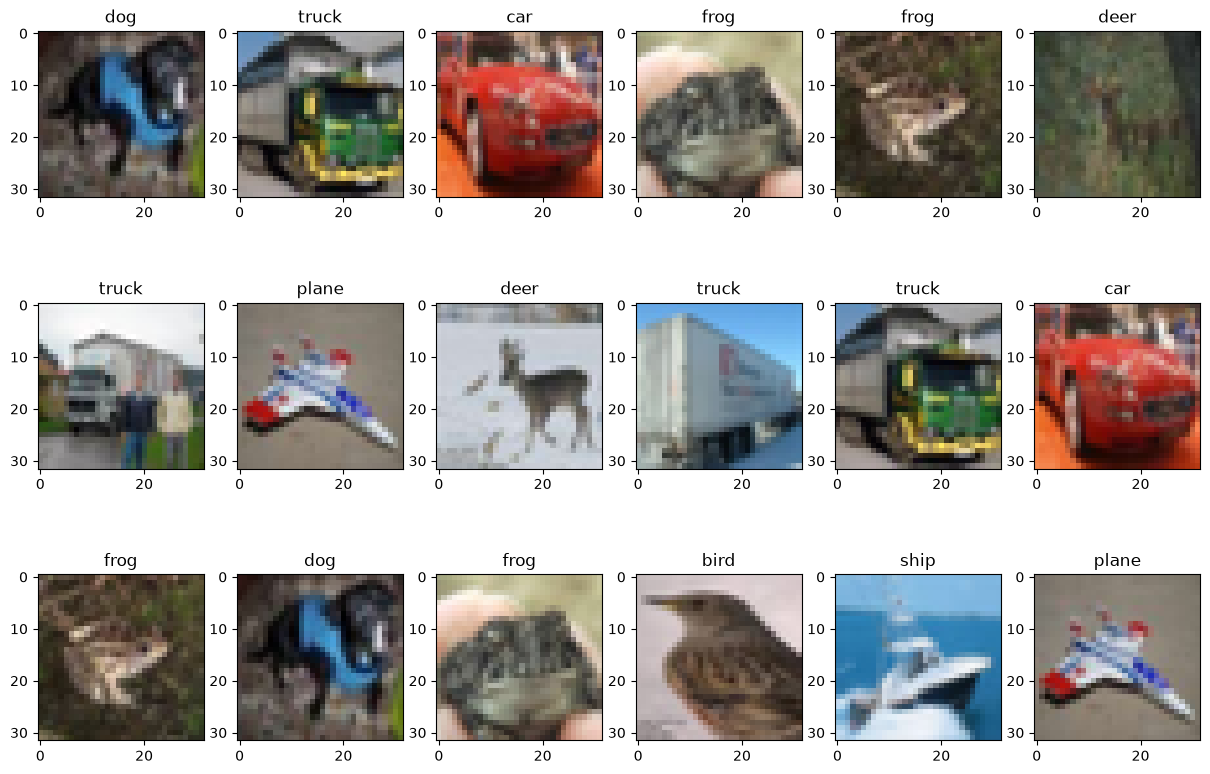

In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Mapping from class ID to class name
classes = {0:'plane', 1:'car', 2:'bird', 3:'cat', 4:'deer',
           5:'dog', 6:'frog', 7:'horse', 8:'ship', 9:'truck'}

print(x_train.shape)
print(y_train.shape)

# Dataset params
num_classes = len(classes)
size = x_train.shape[1]

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):    
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = idx = np.random.randint(0, size)
    # Show the image and the label
    plt.imshow(x_train[idx, ...])
    plt.title(classes[int(y_train[idx].item())])

Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

([<matplotlib.axis.XTick at 0x21f78435bd0>,
 [Text(6, 0, 'frog'),
  Text(9, 0, 'truck'),
  Text(4, 0, 'deer'),
  Text(1, 0, 'car'),
  Text(2, 0, 'bird'),
  Text(7, 0, 'horse'),
  Text(8, 0, 'ship'),
  Text(3, 0, 'cat'),
  Text(5, 0, 'dog'),
  Text(0, 0, 'plane')])

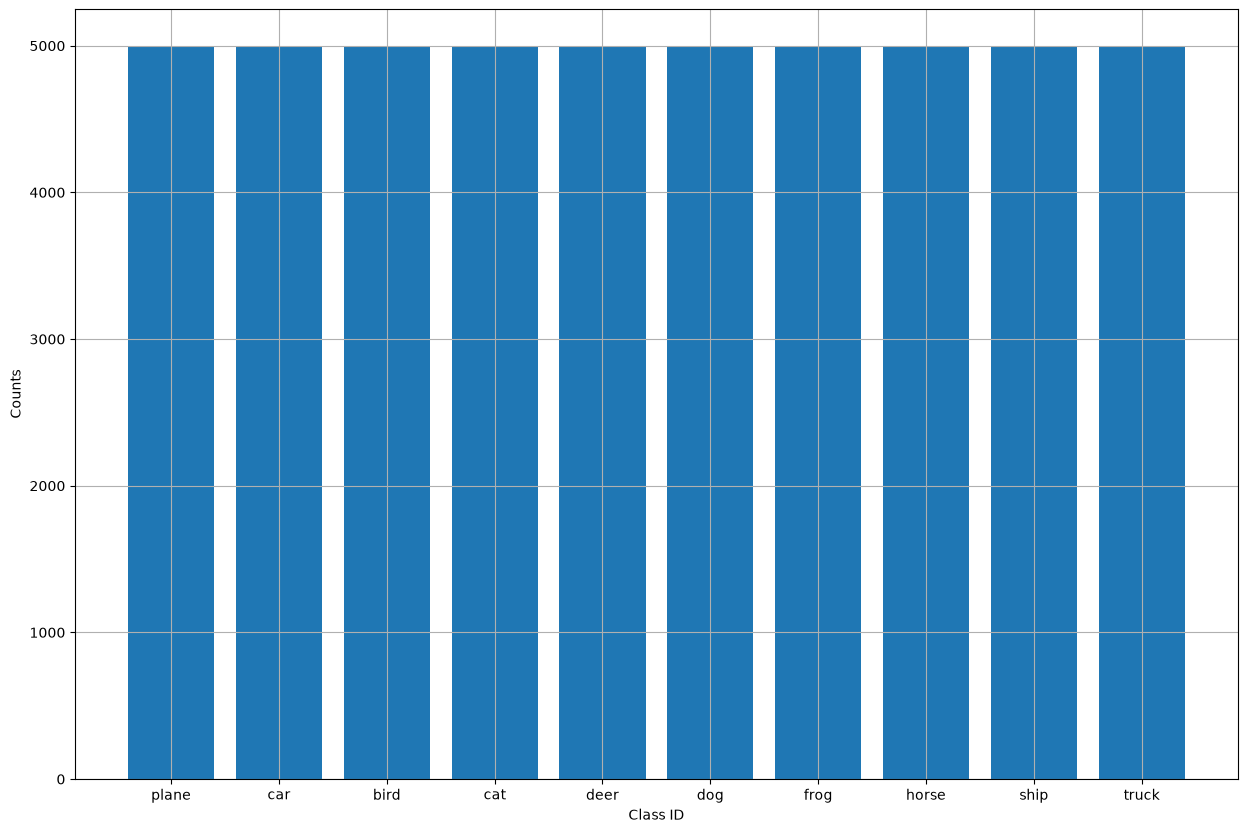

In [3]:
# Compute the class histogram
hist = Counter(y_train.ravel())
plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.xlabel('Class ID'), plt.ylabel('Counts')
class_names = [classes[k] for k in hist.keys()]
plt.xticks(list(hist.keys()), class_names)

### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [4]:
# Normalization
x_train = x_train/255
x_test = x_test/255

# One-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

In [16]:
# Build the classifier
inputs = Input(shape=(size, size, 3))
net = Conv2D(16, kernel_size=(3, 3), activation="relu")(inputs)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Conv2D(32, kernel_size=(3, 3), activation="relu")(net)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Conv2D(64, kernel_size=(3, 3), activation="relu")(net)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Flatten()(net)
outputs = Dense(num_classes, activation="softmax")(net)
model = Model(inputs, outputs)
# Show the model
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_22 (Conv2D)                   │ (None, 30, 30, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_18 (MaxPooling2D)      │ (None, 15, 15, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_23 (Conv2D)                   │ (None, 13, 13, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_19 (MaxPooling2D)      │ (None, 6, 6, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_24 (Conv2D)                   │ (None, 4, 4, 64)            │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_20 (MaxPooling2D)      │ (None, 2, 2, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,154 (102.16 KB)

 Trainable params: 26,154 (102.16 KB)

 Non-trainable params: 0 (0.00 B)

### Step 3: Training

Compile the model and train it.

In [17]:
epochs = 40
batch_size = 128

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
# Train the model
start = time()
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)
print('Elapsed time', time() - start)

Epoch 1/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3520 - loss: 1.7879 - val_accuracy: 0.4376 - val_loss: 1.5993
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4828 - loss: 1.4493 - val_accuracy: 0.5006 - val_loss: 1.4340
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5286 - loss: 1.3345 - val_accuracy: 0.5316 - val_loss: 1.3395
Epoch 4/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5599 - loss: 1.2548 - val_accuracy: 0.5702 - val_loss: 1.2302
Epoch 5/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5828 - loss: 1.1924 - val_accuracy: 0.5956 - val_loss: 1.1755
Epoch 6/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5999 - loss: 1.1438 - val_accuracy: 0.6086 - val_loss: 1.1367
Epoch 7/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6139 - loss: 1.1032 - val_accuracy: 0.6202 - val_loss: 1.1111
Epoch 8/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6284 - loss: 1.0659 - val_accuracy: 0.

Train Acc      0.7833555340766907
Validation Acc 0.6840000152587891


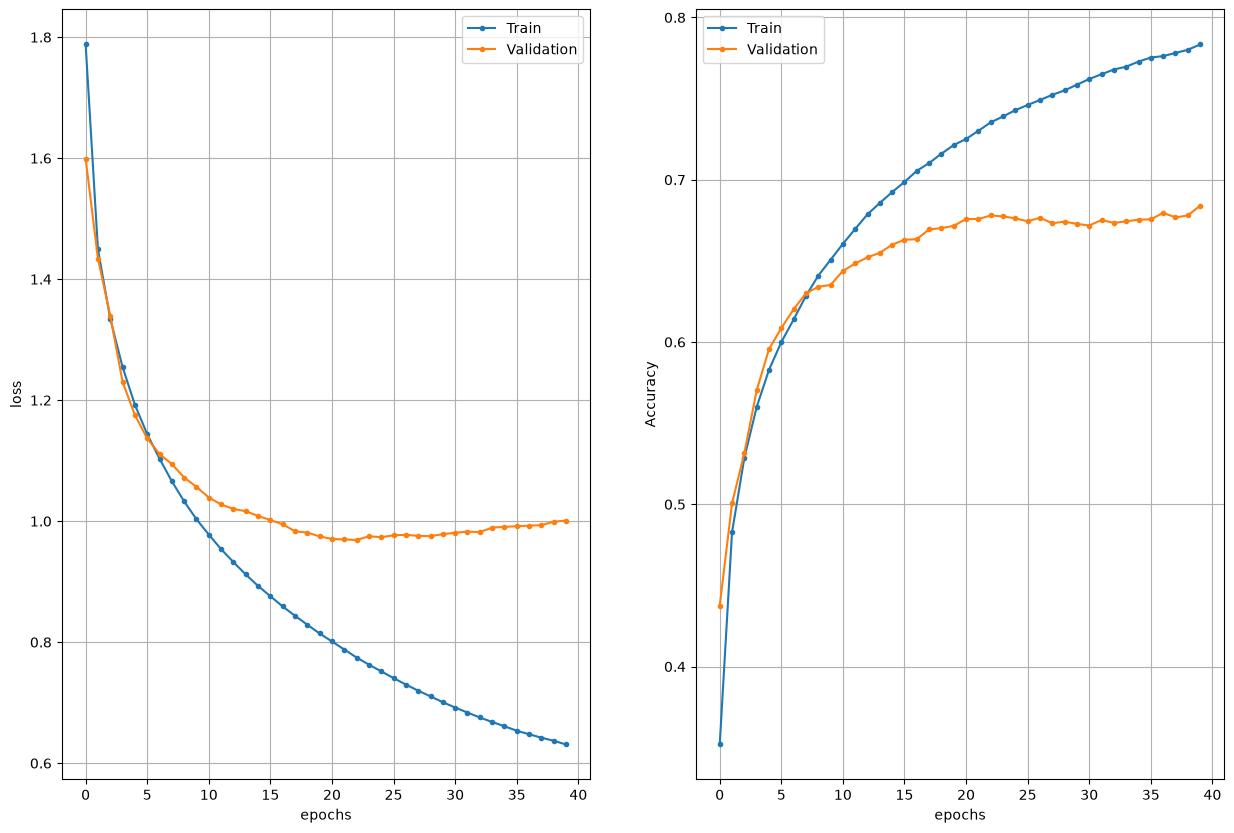

In [19]:
# Show training history (this cell is complete, nothing to implement here :-) )
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                           epochs, h['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])    

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [20]:
# Compute the labels and the predictions as sparse values
y_true = np.argmax(y_test, axis=1)
y_pred = model.predict(x_test)

print('True', y_true[0:5])
print('Pred', np.argmax(y_pred[0:5, :], axis=1))
print('Pred', y_pred[0:5, :])
print(y_pred.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
True [3 8 8 0 6]
Pred [3 8 8 0 6]
Pred [[1.2150236e-02 1.1165735e-03 4.5226134e-02 8.1499821e-01 4.9774483e-04
  4.8859790e-02 6.7834973e-02 1.4607841e-04 8.1220455e-03 1.0481619e-03]
 [2.6420387e-02 1.3156289e-02 2.8339801e-07 1.4516752e-10 7.3725834e-09
  2.0166809e-11 7.6397905e-10 5.7221961e-08 9.6039331e-01 2.9800747e-05]
 [5.4251924e-03 6.8495721e-03 2.8827382e-04 1.1726040e-05 4.7682970e-05
  6.7147671e-06 1.6432090e-05 2.6525702e-05 9.7381401e-01 1.3513828e-02]
 [8.6774993e-01 5.7504009e-02 8.4971718e-04 6.0332254e-06 4.4873837e-04
  1.4883729e-08 4.0685450e-06 2.1024143e-06 7.3408067e-02 2.7225031e-05]
 [3.2553551e-06 1.4393397e-05 8.9211203e-03 2.3800032e-03 1.2608859e-01
  2.0761281e-04 8.6232507e-01 1.0722145e-05 4.4598808e-05 4.5820252e-06]]
(10000, 10)


In [21]:
# Compute and print the accuracy for each class
y_pred = np.argmax(y_pred, axis=1)
for class_id, class_name in classes.items():
    mask = y_true == class_id
    tp = np.sum(y_pred[mask] == class_id)
    total = np.sum(mask)
    acc = tp / total
    print(class_name, acc)

plane 0.696
car 0.813
bird 0.576
cat 0.396
deer 0.695
dog 0.616
frog 0.765
horse 0.663
ship 0.774
truck 0.738


In [22]:
# Print the overall stats
ev = model.evaluate(x_test, y_test)
print('Test loss  ', ev[0])
print('Test metric', ev[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6732 - loss: 1.0227
Test loss   1.0227018594741821
Test metric 0.6732000112533569


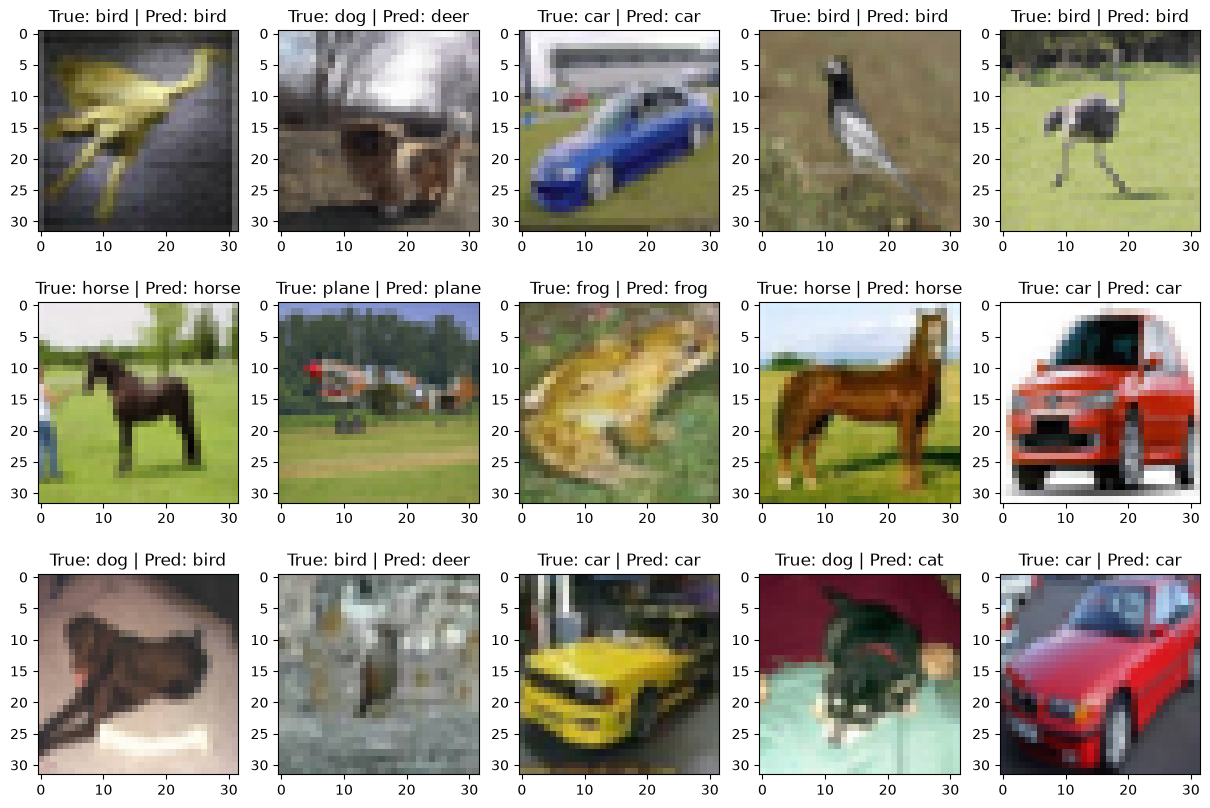

In [23]:
# Show random samples
for ii in range(15):
    # Pick a random sample
    idx = np.random.randint(0, len(y_pred))
    # Show the results
    plt.subplot(3,5,ii+1), plt.imshow(x_test[idx, ...])
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

### Questions
* What is the overall accuracy of the classifier?
  If we use the preset that we used on the lecture, we get a 66% accuracy of the clasifier, meaning 2/3 predictions are basically right for the model we've built.
* What modifications would you do in order to improve the classification accuracy?
  Tricky question, especially after we have discussed on the next lecture the possible improvements (batch normalization, dropout and data augmentation), but for now we can try to increase the number of neurons per layer, and as well add some layers to the model, increase the number of epochs to train.
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?

  This model was trained for 25 epochs and has the following architecture and has accuracy of 69%, but we can see that loss is having fluctuations and does not change, seems like a case of overfitting

  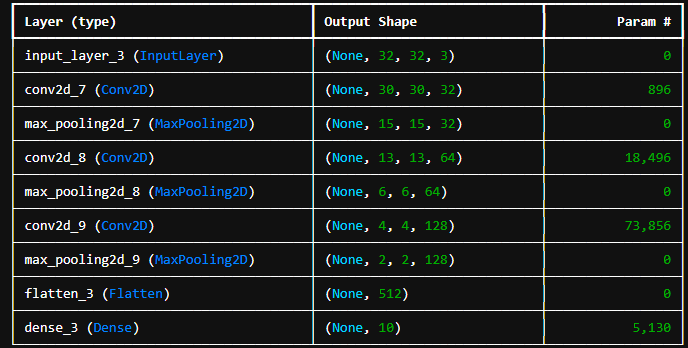

  Overfitting

  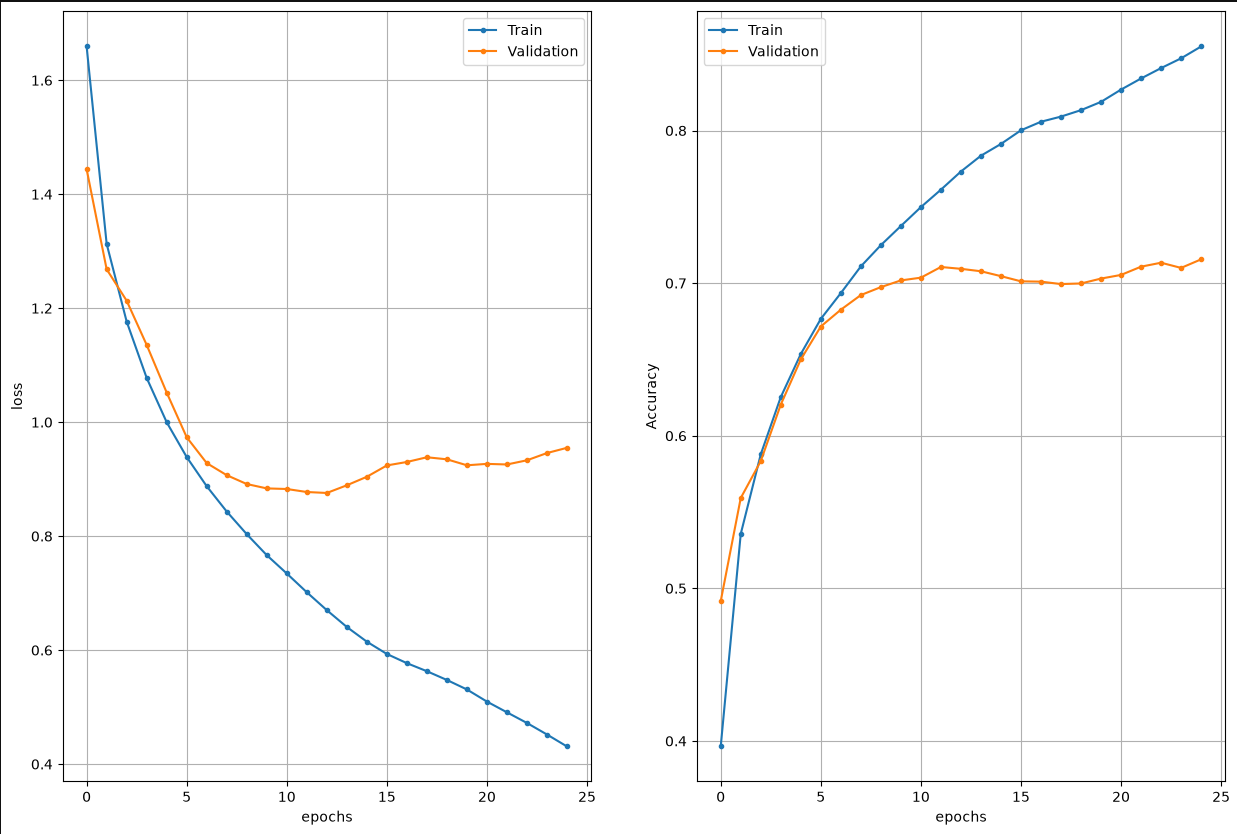

  This model was trained for 40 epochs and has accuracy of 67%

  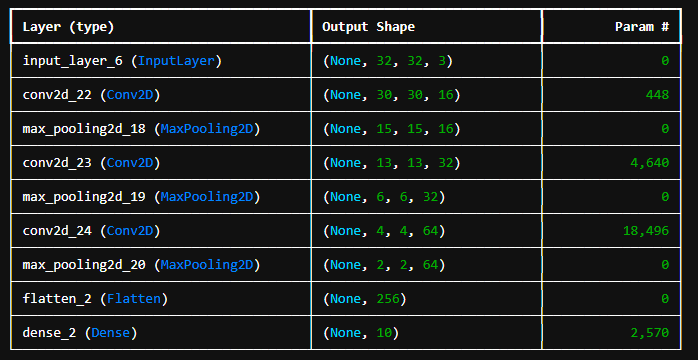


  Overfitting, we can se another example of overfitting
  
  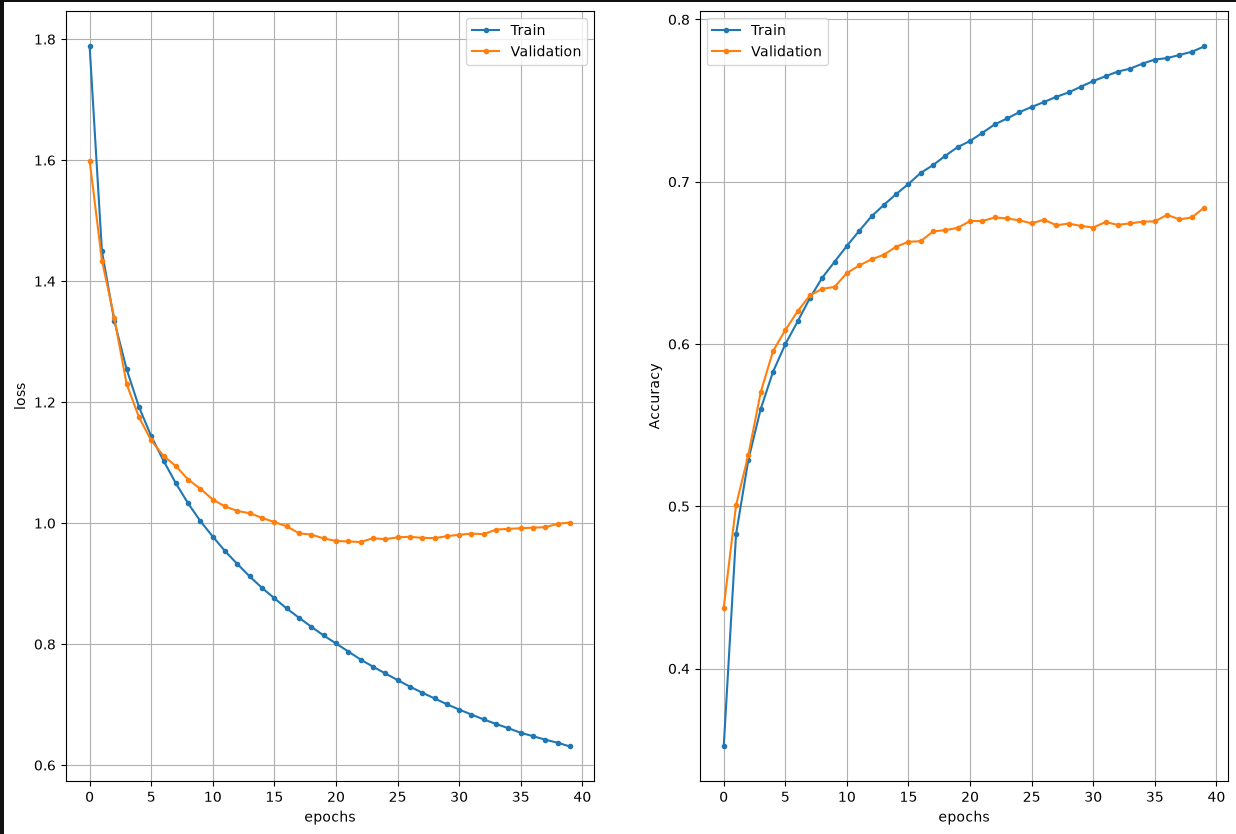

  As a conclustion I would say that trying to squeeze more accoracy without addditional techniques will not bring significant results for us - by making nore neurons or layers or epochs to train will lead to the overfitting, meaning our model will work worse with a new validation data and will keep memorazing the training data set!